In [2]:
from pathlib import Path
import copy
import json
import os
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import swin_t, Swin_T_Weights

DEVICE = torch.device("cuda")
GPU_NAME = torch.cuda.get_device_name(0)


C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Confirming CUDA is being used

In [3]:
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("GPU:", GPU_NAME)
print("Device:", DEVICE)

PyTorch: 2.14.0+cu130
CUDA: 13.0
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
Device: cuda


## 2. Reproducibility and project paths

In [4]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

def find_project_root(start=None):
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Could not find pyproject.toml.")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models" / "swin_t_hparam"
REPORT_DIR = PROJECT_ROOT / "reports" / "swin_t_hparam"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)

Project root: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development


## 3. Loading saved baseline split

In [5]:
SPLIT_PATH = DATA_DIR / "interim" / "compcars_resnet50_baseline_split.csv"

if not SPLIT_PATH.exists():
    raise FileNotFoundError(f"Missing split file: {SPLIT_PATH}")

df = pd.read_csv(SPLIT_PATH)

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

NUM_CLASSES = df["target"].nunique()

class_names = (
    df[["target", "class_name"]]
    .drop_duplicates()
    .sort_values("target")["class_name"]
    .tolist()
)

print("Rows:", len(df))
print("Classes:", NUM_CLASSES)
print("Train / Val / Test:", len(train_df), len(val_df), len(test_df))

Rows: 2000
Classes: 20
Train / Val / Test: 1600 200 200


## 4. Configure CompCars image path

In [6]:
DEFAULT_COMPCARS = (
    r"G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J"
    r"\capstone-vehicle-metadata\data\compcars_kaggle\extracted"
)

LOCAL_COMPCARS_EXTRACTED = Path(
    os.environ.get("COMPCARS_EXTRACTED", DEFAULT_COMPCARS)
)

if not LOCAL_COMPCARS_EXTRACTED.exists():
    raise FileNotFoundError(
        f"CompCars path does not exist:\n{LOCAL_COMPCARS_EXTRACTED}"
    )

def resolve_local_path(original_path):
    text = str(original_path).replace("\\", "/")

    if "/extracted/" in text:
        relative = text.split("/extracted/", 1)[1]
    elif "/image/" in text:
        relative = "image/" + text.split("/image/", 1)[1]
    else:
        return Path(original_path)

    return LOCAL_COMPCARS_EXTRACTED / Path(*relative.split("/"))

for part in [train_df, val_df, test_df]:
    part["local_file_path"] = part["file_path"].map(resolve_local_path)

sample = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True,
).sample(30, random_state=SEED)

exists = sample["local_file_path"].map(Path.exists)

print("Checked:", len(sample))
print("Existing:", int(exists.sum()))
print("Missing:", int((~exists).sum()))

if not exists.all():
    raise FileNotFoundError("Some image paths do not resolve.")

print("Image path mapping looks good.")

Checked: 30
Existing: 30
Missing: 0
Image path mapping looks good.


## 5. Swin-T experiment configurations

In [7]:
EXPERIMENTS = [
    {
        "name": "baseline",
        "finetune_lr": 5e-5,
        "weight_decay": 1e-4,
        "unfreeze_depth": "last_stage",
        "label_smoothing": 0.1,
        "augmentation": "standard",
        "stage2_epochs": 3,
    },
    {
        "name": "lr_1e-5",
        "finetune_lr": 1e-5,
        "weight_decay": 1e-4,
        "unfreeze_depth": "last_stage",
        "label_smoothing": 0.1,
        "augmentation": "standard",
        "stage2_epochs": 3,
    },
    {
        "name": "lr_1e-4",
        "finetune_lr": 1e-4,
        "weight_decay": 1e-4,
        "unfreeze_depth": "last_stage",
        "label_smoothing": 0.1,
        "augmentation": "standard",
        "stage2_epochs": 3,
    },
    {
        "name": "unfreeze_2_stages",
        "finetune_lr": 3e-5,
        "weight_decay": 1e-4,
        "unfreeze_depth": "last_2_stages",
        "label_smoothing": 0.1,
        "augmentation": "standard",
        "stage2_epochs": 3,
    },
    {
        "name": "unfreeze_3_stages",
        "finetune_lr": 2e-5,
        "weight_decay": 1e-4,
        "unfreeze_depth": "last_3_stages",
        "label_smoothing": 0.1,
        "augmentation": "standard",
        "stage2_epochs": 3,
    },
    {
        "name": "no_label_smoothing",
        "finetune_lr": 5e-5,
        "weight_decay": 1e-4,
        "unfreeze_depth": "last_stage",
        "label_smoothing": 0.0,
        "augmentation": "standard",
        "stage2_epochs": 3,
    },
    {
        "name": "strong_augmentation",
        "finetune_lr": 5e-5,
        "weight_decay": 1e-4,
        "unfreeze_depth": "last_stage",
        "label_smoothing": 0.1,
        "augmentation": "strong",
        "stage2_epochs": 3,
    },
    {
        "name": "weight_decay_1e-5",
        "finetune_lr": 5e-5,
        "weight_decay": 1e-5,
        "unfreeze_depth": "last_stage",
        "label_smoothing": 0.1,
        "augmentation": "standard",
        "stage2_epochs": 3,
    },
    {
        "name": "longer_finetune",
        "finetune_lr": 3e-5,
        "weight_decay": 1e-4,
        "unfreeze_depth": "last_2_stages",
        "label_smoothing": 0.1,
        "augmentation": "standard",
        "stage2_epochs": 6,
    },
]

display(pd.DataFrame(EXPERIMENTS))

,name,finetune_lr,weight_decay,unfreeze_depth,label_smoothing,augmentation,stage2_epochs
0,baseline,0.00005,0.00010,last_stage,0.1,standard,3
1,lr_1e-5,0.00001,0.00010,last_stage,0.1,standard,3
2,lr_1e-4,0.00010,0.00010,last_stage,0.1,standard,3
3,unfreeze_2_stages,0.00003,0.00010,last_2_stages,0.1,standard,3
4,unfreeze_3_stages,0.00002,0.00010,last_3_stages,0.1,standard,3
5,no_label_smoothing,0.00005,0.00010,last_stage,0.0,standard,3
6,strong_augmentation,0.00005,0.00010,last_stage,0.1,strong,3
7,weight_decay_1e-5,0.00005,0.00001,last_stage,0.1,standard,3
8,longer_finetune,0.00003,0.00010,last_2_stages,0.1,standard,6


## 6. Transforms and dataset

In [8]:
IMAGE_SIZE = 224
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

def make_train_transform(kind):
    if kind == "standard":
        return transforms.Compose([
            transforms.RandomResizedCrop(
                IMAGE_SIZE,
                scale=(0.80, 1.0),
                ratio=(0.85, 1.15),
            ),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.ColorJitter(
                brightness=0.15,
                contrast=0.15,
                saturation=0.10,
            ),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])

    if kind == "strong":
        return transforms.Compose([
            transforms.RandomResizedCrop(
                IMAGE_SIZE,
                scale=(0.70, 1.0),
                ratio=(0.80, 1.20),
            ),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(5),
            transforms.ColorJitter(
                brightness=0.25,
                contrast=0.25,
                saturation=0.20,
                hue=0.03,
            ),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
            transforms.RandomErasing(
                p=0.20,
                scale=(0.02, 0.10),
            ),
        ])

    raise ValueError(kind)

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class CompCarsDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        image = Image.open(row["local_file_path"]).convert("RGB")
        return self.transform(image), int(row["target"])

## 7. DataLoaders

In [10]:
BATCH_SIZE = 16
NUM_WORKERS = 0

def make_loaders(augmentation):
    train_loader = DataLoader(
        CompCarsDataset(
            train_df,
            make_train_transform(augmentation),
        ),
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    val_loader = DataLoader(
        CompCarsDataset(val_df, eval_transform),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    test_loader = DataLoader(
        CompCarsDataset(test_df, eval_transform),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    return train_loader, val_loader, test_loader

print("Batch size:", BATCH_SIZE)

Batch size: 16


## 8. Building and configuring fine-tuning depth for Swin-T

In [12]:
def build_swin():
    model = swin_t(weights=Swin_T_Weights.DEFAULT)

    for parameter in model.parameters():
        parameter.requires_grad = False

    model.head = nn.Linear(
        model.head.in_features,
        NUM_CLASSES,
    )

    return model.to(DEVICE)


def configure_stage2_unfreezing(model, depth):
    for parameter in model.head.parameters():
        parameter.requires_grad = True

    for parameter in model.norm.parameters():
        parameter.requires_grad = True

    if depth == "last_stage":
        modules = [
            model.features[7],
        ]

    elif depth == "last_2_stages":
        # Stage 3 -> patch merge -> Stage 4
        modules = [
            model.features[5],
            model.features[6],
            model.features[7],
        ]

    elif depth == "last_3_stages":
        # Stage 2 -> merge -> Stage 3 -> merge -> Stage 4
        modules = [
            model.features[3],
            model.features[4],
            model.features[5],
            model.features[6],
            model.features[7],
        ]

    else:
        raise ValueError(f"Unknown unfreeze depth: {depth}")

    for module in modules:
        for parameter in module.parameters():
            parameter.requires_grad = True


def count_trainable(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

## 9. Training utilities

In [13]:
def topk_correct(logits, targets, k=5):
    k = min(k, logits.shape[1])
    indices = logits.topk(k, dim=1).indices
    return (
        indices
        .eq(targets.view(-1, 1))
        .any(dim=1)
        .sum()
        .item()
    )


def run_epoch(
    model,
    loader,
    criterion,
    optimizer=None,
    scaler=None,
):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    top1_correct = 0
    top5_correct = 0
    samples = 0

    for images, targets in tqdm(loader, leave=False):
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=True,
        ):
            logits = model(images)
            loss = criterion(logits, targets)

        if training:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

        batch_size = images.size(0)

        total_loss += loss.item() * batch_size
        top1_correct += (
            logits.argmax(dim=1) == targets
        ).sum().item()
        top5_correct += topk_correct(
            logits,
            targets,
            k=5,
        )
        samples += batch_size

    return {
        "loss": total_loss / samples,
        "top1": top1_correct / samples,
        "top5": top5_correct / samples,
    }


def train_epochs(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs,
    stage_name,
):
    scaler = torch.amp.GradScaler("cuda", enabled=True)

    history = []
    best_val_top1 = -1.0
    best_state = None

    for epoch in range(1, epochs + 1):
        start = time.perf_counter()

        train_metrics = run_epoch(
            model,
            train_loader,
            criterion,
            optimizer=optimizer,
            scaler=scaler,
        )

        with torch.inference_mode():
            val_metrics = run_epoch(
                model,
                val_loader,
                criterion,
            )

        elapsed = time.perf_counter() - start

        row = {
            "stage": stage_name,
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_top1": train_metrics["top1"],
            "train_top5": train_metrics["top5"],
            "val_loss": val_metrics["loss"],
            "val_top1": val_metrics["top1"],
            "val_top5": val_metrics["top5"],
            "seconds": elapsed,
        }

        history.append(row)

        print(
            f"[{stage_name}] epoch {epoch}/{epochs} | "
            f"train={row['train_top1']:.3f} "
            f"val={row['val_top1']:.3f} "
            f"top5={row['val_top5']:.3f} | "
            f"{elapsed:.1f}s"
        )

        if row["val_top1"] > best_val_top1:
            best_val_top1 = row["val_top1"]
            best_state = copy.deepcopy(
                model.state_dict()
            )

    model.load_state_dict(best_state)

    return history, best_val_top1, best_state

## 10. Running the hyperparameter search

In [14]:
STAGE1_EPOCHS = 3
HEAD_LR = 1e-3

search_results = []

for config in EXPERIMENTS:
    print("\n" + "=" * 80)
    print("EXPERIMENT:", config["name"])
    print(config)
    print("=" * 80)

    train_loader, val_loader, _ = make_loaders(
        config["augmentation"]
    )

    model = build_swin()

    criterion = nn.CrossEntropyLoss(
        label_smoothing=config["label_smoothing"]
    )

    # Stage 1: classification head only
    optimizer = torch.optim.AdamW(
        model.head.parameters(),
        lr=HEAD_LR,
        weight_decay=config["weight_decay"],
    )

    history1, val1, state1 = train_epochs(
        model,
        train_loader,
        val_loader,
        criterion,
        optimizer,
        STAGE1_EPOCHS,
        "head",
    )

    # Stage 2: configured Swin fine-tuning
    configure_stage2_unfreezing(
        model,
        config["unfreeze_depth"],
    )

    print(
        "Stage 2 trainable parameters:",
        f"{count_trainable(model):,}",
    )

    optimizer = torch.optim.AdamW(
        filter(
            lambda parameter: parameter.requires_grad,
            model.parameters(),
        ),
        lr=config["finetune_lr"],
        weight_decay=config["weight_decay"],
    )

    history2, val2, state2 = train_epochs(
        model,
        train_loader,
        val_loader,
        criterion,
        optimizer,
        config["stage2_epochs"],
        "fine_tune",
    )

    if val1 > val2:
        selected_stage = "head"
        selected_val = val1
        selected_state = state1
    else:
        selected_stage = "fine_tune"
        selected_val = val2
        selected_state = state2

    checkpoint_path = (
        MODEL_DIR / f"{config['name']}_best.pt"
    )

    torch.save(
        {
            "architecture": "swin_t",
            "state_dict": selected_state,
            "config": config,
            "validation_top1": float(selected_val),
            "selected_stage": selected_stage,
            "classes": class_names,
            "num_classes": NUM_CLASSES,
        },
        checkpoint_path,
    )

    search_results.append({
        **config,
        "selected_stage": selected_stage,
        "validation_top1": selected_val,
        "checkpoint": str(checkpoint_path),
        "total_seconds": sum(
            row["seconds"]
            for row in history1 + history2
        ),
    })

    del model
    torch.cuda.empty_cache()

search_df = (
    pd.DataFrame(search_results)
    .sort_values(
        "validation_top1",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(search_df)

search_df.to_csv(
    REPORT_DIR / "hyperparameter_search.csv",
    index=False,
)


EXPERIMENT: baseline
{'name': 'baseline', 'finetune_lr': 5e-05, 'weight_decay': 0.0001, 'unfreeze_depth': 'last_stage', 'label_smoothing': 0.1, 'augmentation': 'standard', 'stage2_epochs': 3}


[head] epoch 1/3 | train=0.198 val=0.250 top5=0.715 | 73.9s


[head] epoch 2/3 | train=0.404 val=0.415 top5=0.790 | 56.7s


[head] epoch 3/3 | train=0.497 val=0.465 top5=0.850 | 54.6s
Stage 2 trainable parameters: 14,200,772


[fine_tune] epoch 1/3 | train=0.610 val=0.655 top5=0.940 | 56.9s


...

[fine_tune] epoch 3/6 | train=0.905 val=0.820 top5=0.975 | 47.2s


[fine_tune] epoch 4/6 | train=0.945 val=0.855 top5=0.985 | 47.1s


[fine_tune] epoch 5/6 | train=0.964 val=0.870 top5=0.990 | 47.4s


[fine_tune] epoch 6/6 | train=0.979 val=0.870 top5=0.990 | 47.4s


,name,finetune_lr,weight_decay,unfreeze_depth,label_smoothing,augmentation,stage2_epochs,selected_stage,validation_top1,checkpoint,total_seconds
0,longer_finetune,0.00003,0.00010,last_2_stages,0.1,standard,6,fine_tune,0.870,C:\Users\elesh\Academics\UTS\36127InnovationLa...,416.112525
1,unfreeze_2_stages,0.00003,0.00010,last_2_stages,0.1,standard,3,fine_tune,0.805,C:\Users\elesh\Academics\UTS\36127InnovationLa...,272.311013
2,lr_1e-4,0.00010,0.00010,last_stage,0.1,standard,3,fine_tune,0.790,C:\Users\elesh\Academics\UTS\36127InnovationLa...,265.175478
3,weight_decay_1e-5,0.00005,0.00001,last_stage,0.1,standard,3,fine_tune,0.765,C:\Users\elesh\Academics\UTS\36127InnovationLa...,264.535457
4,unfreeze_3_stages,0.00002,0.00010,last_3_stages,0.1,standard,3,fine_tune,0.760,C:\Users\elesh\Academics\UTS\36127InnovationLa...,274.990300
5,no_label_smoothing,0.00005,0.00010,last_stage,0.0,standard,3,fine_tune,0.755,C:\Users\elesh\Academics\UTS\36127InnovationLa...,264.605524
6,strong_augmentation,0.00005,0.00010,last_stage,0.1,strong,3,fine_tune,0.745,C:\Users\elesh\Academics\UTS\36127InnovationLa...,288.783013
7,baseline,0.00005,0.00010,last_stage,0.1,standard,3,fine_tune,0.730,C:\Users\elesh\Academics\UTS\36127InnovationLa...,340.218536
8,lr_1e-5,0.00001,0.00010,last_stage,0.1,standard,3,fine_tune,0.620,C:\Users\elesh\Academics\UTS\36127InnovationLa...,267.011220


## 11. Best validation configuration

In [15]:
best = search_df.iloc[0]

print("BEST SWIN-T CONFIGURATION")
display(best.to_frame().T)

BEST SWIN-T CONFIGURATION


,name,finetune_lr,weight_decay,unfreeze_depth,label_smoothing,augmentation,stage2_epochs,selected_stage,validation_top1,checkpoint,total_seconds
0,longer_finetune,0.00003,0.0001,last_2_stages,0.1,standard,6,fine_tune,0.87,C:\Users\elesh\Academics\UTS\36127InnovationLa...,416.112525


## 12. Final held-out test evaluation

In [16]:
best_config = {
    "name": str(best["name"]),
    "finetune_lr": float(best["finetune_lr"]),
    "weight_decay": float(best["weight_decay"]),
    "unfreeze_depth": str(best["unfreeze_depth"]),
    "label_smoothing": float(best["label_smoothing"]),
    "augmentation": str(best["augmentation"]),
    "stage2_epochs": int(best["stage2_epochs"]),
}

_, _, test_loader = make_loaders(
    best_config["augmentation"]
)

model = build_swin()

checkpoint = torch.load(
    best["checkpoint"],
    map_location=DEVICE,
    weights_only=False,
)

model.load_state_dict(
    checkpoint["state_dict"]
)

model.eval()

y_true = []
y_pred = []
all_probabilities = []

with torch.inference_mode():
    for images, targets in tqdm(test_loader):
        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        logits = model(images)
        probabilities = torch.softmax(
            logits,
            dim=1,
        )

        y_true.extend(targets.numpy())
        y_pred.extend(
            probabilities.argmax(dim=1).cpu().numpy()
        )
        all_probabilities.append(
            probabilities.cpu()
        )

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
all_probabilities = torch.cat(
    all_probabilities,
    dim=0,
)

top1 = accuracy_score(y_true, y_pred)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
)

top5_indices = all_probabilities.topk(
    min(5, NUM_CLASSES),
    dim=1,
).indices.numpy()

top5 = np.mean([
    true_target in predicted_top5
    for true_target, predicted_top5
    in zip(y_true, top5_indices)
])

print(f"Best config Test Top-1: {top1:.4f}")
print(f"Best config Test Top-5: {top5:.4f}")
print(f"Best config Macro F1:   {macro_f1:.4f}")

100%|██████████| 13/13 [00:05<00:00,  2.48it/s]

Best config Test Top-1: 0.8500
Best config Test Top-5: 0.9950
Best config Macro F1:   0.8541


## 13. Classification report and confusion matrix

,precision,recall,f1-score,support
Audi | Audi A5 coupe,0.583333,0.70,0.636364,10.00
Audi | Audi A5 hatchback,0.461538,0.60,0.521739,10.00
Audi | Audi A8L,0.900000,0.90,0.900000,10.00
BAW | BAW E Series hatchback,1.000000,0.80,0.888889,10.00
BWM | BWM 3 Series,0.818182,0.90,0.857143,10.00
BWM | BWM 5 Series,0.875000,0.70,0.777778,10.00
Benz | Benz E Class,0.888889,0.80,0.842105,10.00
Benz | Benz E Class couple,0.888889,0.80,0.842105,10.00
Buck | EXCELLE GT,0.714286,1.00,0.833333,10.00
Buck | Lacrosse,0.888889,0.80,0.842105,10.00


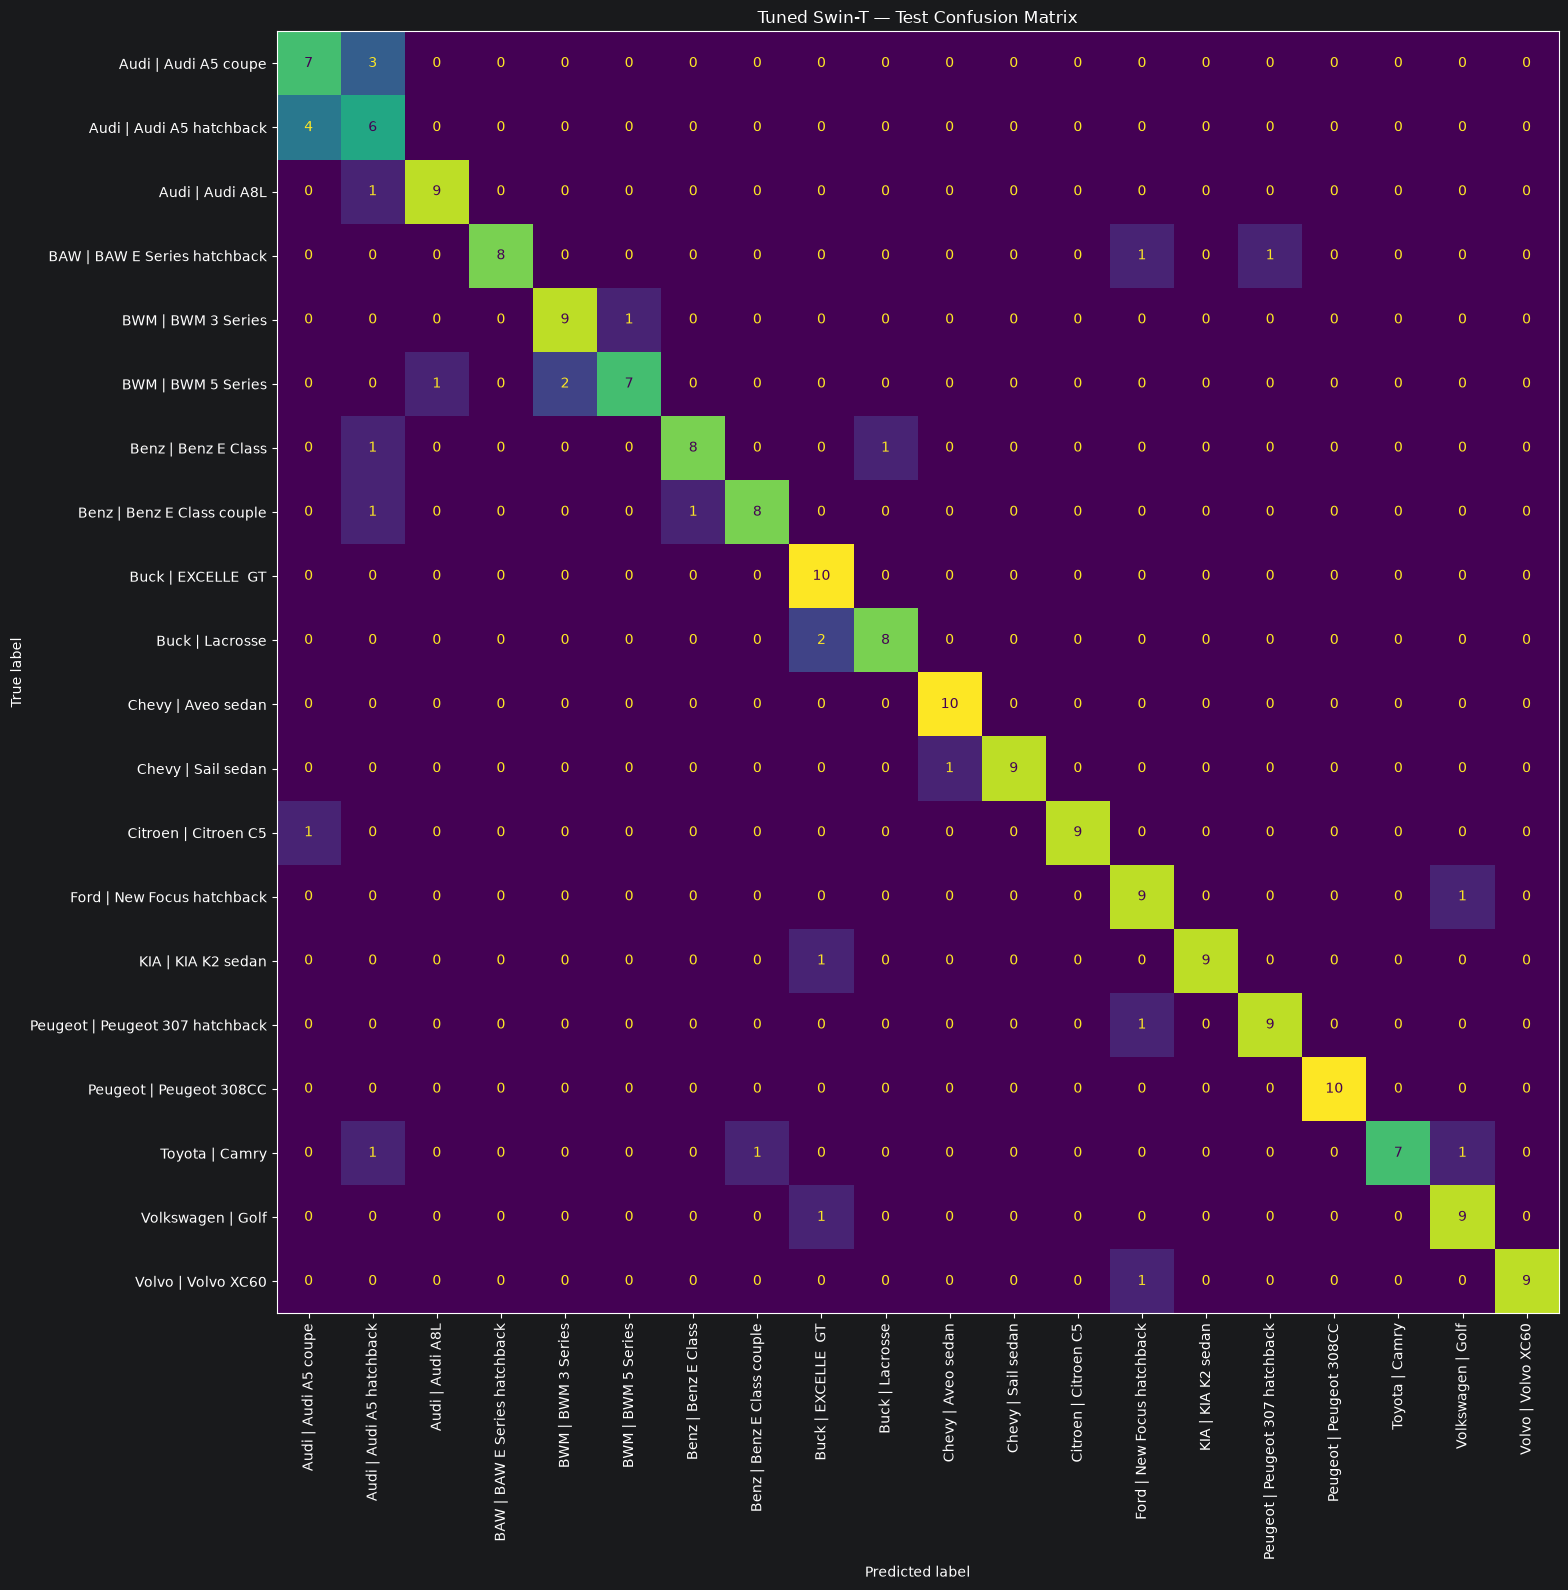

In [17]:
report_df = pd.DataFrame(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )
).T

report_df.to_csv(
    REPORT_DIR
    / "best_config_classification_report.csv"
)

display(report_df)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
)

fig, ax = plt.subplots(figsize=(16, 16))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names,
).plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False,
    values_format="d",
)

ax.set_title(
    "Tuned Swin-T — Test Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR
    / "best_config_confusion_matrix.png",
    dpi=160,
)

plt.show()

## 14. Saving the best tuned Swin-T

In [18]:
def json_converter(obj):
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.bool_):
        return bool(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()

    raise TypeError(
        f"Object of type {type(obj).__name__} "
        f"is not JSON serializable"
    )


final_model_path = (
    MODEL_DIR / "swin_t_best_tuned.pt"
)

torch.save(
    {
        "architecture": "swin_t",
        "state_dict": model.state_dict(),
        "classes": class_names,
        "num_classes": NUM_CLASSES,
        "best_config": best_config,
        "validation_top1": float(
            best["validation_top1"]
        ),
        "test_top1": float(top1),
        "test_top5": float(top5),
        "test_macro_f1": float(macro_f1),
        "gpu": GPU_NAME,
    },
    final_model_path,
)

final_metrics = {
    "architecture": "Swin-T",
    "best_config": best_config,
    "validation_top1": float(
        best["validation_top1"]
    ),
    "test_top1": float(top1),
    "test_top5": float(top5),
    "test_macro_f1": float(macro_f1),
    "gpu": GPU_NAME,
}

metrics_path = (
    REPORT_DIR / "best_config_metrics.json"
)

with metrics_path.open(
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        final_metrics,
        f,
        indent=2,
        default=json_converter,
    )

print("Saved model:", final_model_path)
print("Saved metrics:", metrics_path)

final_metrics

Saved model: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\models\swin_t_hparam\swin_t_best_tuned.pt
Saved metrics: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\reports\swin_t_hparam\best_config_metrics.json


{'architecture': 'Swin-T',
 'best_config': {'name': 'longer_finetune',
  'finetune_lr': 3e-05,
  'weight_decay': 0.0001,
  'unfreeze_depth': 'last_2_stages',
  'label_smoothing': 0.1,
  'augmentation': 'standard',
  'stage2_epochs': 6},
 'validation_top1': 0.87,
 'test_top1': 0.85,
 'test_top5': 0.995,
 'test_macro_f1': 0.8541135068547909,
 'gpu': 'NVIDIA GeForce RTX 5060 Laptop GPU'}